In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import os
import kagglehub

In [3]:
# Plot style: soft light theme with strong contrast
plt.rcParams.update({
    'figure.facecolor': '#f8f9fc',
    'axes.facecolor':   '#ffffff',
    'axes.edgecolor':   '#cfd6e4',
    'axes.labelcolor':  '#2b3245',
    'axes.titlecolor':  '#1b2236',
    'axes.titleweight': 'bold',
    'axes.titlesize':   14,
    'axes.labelsize':   11,
    'axes.grid':        True,
    'axes.spines.top':  False,
    'axes.spines.right': False,
    'xtick.color':      '#5b6478',
    'ytick.color':      '#5b6478',
    'text.color':       '#2b3245',
    'grid.color':       '#e6eaf2',
    'grid.linestyle':   '--',
    'grid.linewidth':   0.8,
    'font.family':      'DejaVu Sans',
    'figure.dpi':       110,
    'savefig.dpi':      300,
    'lines.linewidth':  2,
    # Box plot styling (this is what fixes the visibility)
    'boxplot.boxprops.linewidth':     1.8,
    'boxplot.whiskerprops.linewidth': 1.8,
    'boxplot.capprops.linewidth':     1.8,
    'boxplot.medianprops.linewidth':  2.5,
    'boxplot.medianprops.color':      '#e8590c',
    'boxplot.flierprops.marker':      'o',
    'boxplot.flierprops.markersize':  4,
    'boxplot.flierprops.markerfacecolor': '#e03131',
    'boxplot.flierprops.markeredgecolor': 'none',
})

# Vibrant palette that works on a light background
ACCENT   = '#3b82f6'   # blue
GREEN    = '#10b981'   # emerald
RED      = '#ef4444'   # red
ORANGE   = '#f59e0b'   # amber
PURPLE   = '#8b5cf6'   # violet
TEAL     = '#14b8a6'

PALETTE = [ACCENT, GREEN, ORANGE, PURPLE, RED, TEAL]
sns.set_palette(PALETTE)

print('Libraries loaded successfully')

Libraries loaded successfully


In [4]:
df = pd.read_csv("/kaggle/input/datasets/jayjoshi37/sleep-screen-time-and-stress-analysis/sleep_mobile_stress_dataset_15000.csv")
df.head()

,user_id,age,gender,occupation,daily_screen_time_hours,phone_usage_before_sleep_minutes,sleep_duration_hours,sleep_quality_score,stress_level,caffeine_intake_cups,physical_activity_minutes,notifications_received_per_day,mental_fatigue_score
0,1,56,Female,Designer,3.26,86,5.31,7.72,3.49,0,35,119,3.57
1,2,46,Female,Teacher,1.85,32,7.36,9.70,3.01,0,16,299,1.91
2,3,32,Female,Designer,3.04,107,4.50,6.38,5.03,0,17,21,6.05
3,4,25,Male,Software Engineer,9.00,36,6.68,5.53,10.00,0,3,220,9.92
4,5,38,Female,Teacher,3.52,56,7.57,6.69,6.71,4,92,167,5.99


In [5]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   user_id                           15000 non-null  int64  
 1   age                               15000 non-null  int64  
 2   gender                            15000 non-null  object 
 3   occupation                        15000 non-null  object 
 4   daily_screen_time_hours           15000 non-null  float64
 5   phone_usage_before_sleep_minutes  15000 non-null  int64  
 6   sleep_duration_hours              15000 non-null  float64
 7   sleep_quality_score               15000 non-null  float64
 8   stress_level                      15000 non-null  float64
 9   caffeine_intake_cups              15000 non-null  int64  
 10  physical_activity_minutes         15000 non-null  int64  
 11  notifications_received_per_day    15000 non-null  int64  
 12  ment

None

- Only `Gender` and `occupation` is object datatype

In [6]:
print("Total Unique Gender:",df['gender'].nunique())
print("Total Unique number of occupation:",df['occupation'].nunique(),end='\n\n')

print(df['gender'].value_counts(),end="\n\n")
print(df['occupation'].value_counts())

Total Unique Gender: 3
Total Unique number of occupation: 8

gender
Male      7234
Female    7181
Other      585
Name: count, dtype: int64

occupation
Manager              1962
Doctor               1922
Software Engineer    1917
Freelancer           1891
Student              1861
Researcher           1837
Designer             1813
Teacher              1797
Name: count, dtype: int64


In [7]:
df.isna().sum()

user_id                             0
age                                 0
gender                              0
occupation                          0
daily_screen_time_hours             0
phone_usage_before_sleep_minutes    0
sleep_duration_hours                0
sleep_quality_score                 0
stress_level                        0
caffeine_intake_cups                0
physical_activity_minutes           0
notifications_received_per_day      0
mental_fatigue_score                0
dtype: int64

- No Empty Values

In [8]:
df.duplicated().sum()

np.int64(0)

- There's no duplicate values

### Univariate Analysis

In [9]:
summary = df.describe().T

summary['mean_median_diff'] = (
    summary['mean'] - summary['50%']
)

display(summary)

,count,mean,std,min,25%,50%,75%,max,mean_median_diff
user_id,15000.0,7500.500000,4330.271354,1.0,3750.75,7500.50,11250.25,15000.0,0.000000
age,15000.0,38.488467,12.007970,18.0,28.00,38.00,49.00,59.0,0.488467
daily_screen_time_hours,15000.0,5.501528,2.600085,1.0,3.26,5.49,7.76,10.0,0.011528
phone_usage_before_sleep_minutes,15000.0,59.708933,34.641858,0.0,29.00,60.00,90.00,119.0,-0.291067
sleep_duration_hours,15000.0,6.509683,1.452689,4.0,5.26,6.49,7.79,9.0,0.019683
sleep_quality_score,15000.0,6.246362,1.713644,1.0,5.00,6.25,7.50,10.0,-0.003638
stress_level,15000.0,6.980247,2.749382,1.0,4.75,7.38,10.00,10.0,-0.399753
caffeine_intake_cups,15000.0,1.998800,1.414590,0.0,1.00,2.00,3.00,4.0,-0.001200
physical_activity_minutes,15000.0,59.157133,34.525705,0.0,29.00,59.00,89.00,119.0,0.157133
notifications_received_per_day,15000.0,160.890467,80.856902,20.0,92.00,162.00,231.00,299.0,-1.109533


In [10]:
skewed_cols = summary[np.abs(summary['mean_median_diff']) > 0.35].index.tolist()

for col in skewed_cols:
    print(f"{col}: {df[col].skew():.3f}")

age: 0.008
stress_level: -0.466
notifications_received_per_day: -0.020
mental_fatigue_score: -0.511


- `age` and `notifications_received_per_day` is close to 0, means they are approximately symmetric
- `mental_fatigue_score` and `stress_level` is less than 0; means it's negative skew (left skew)

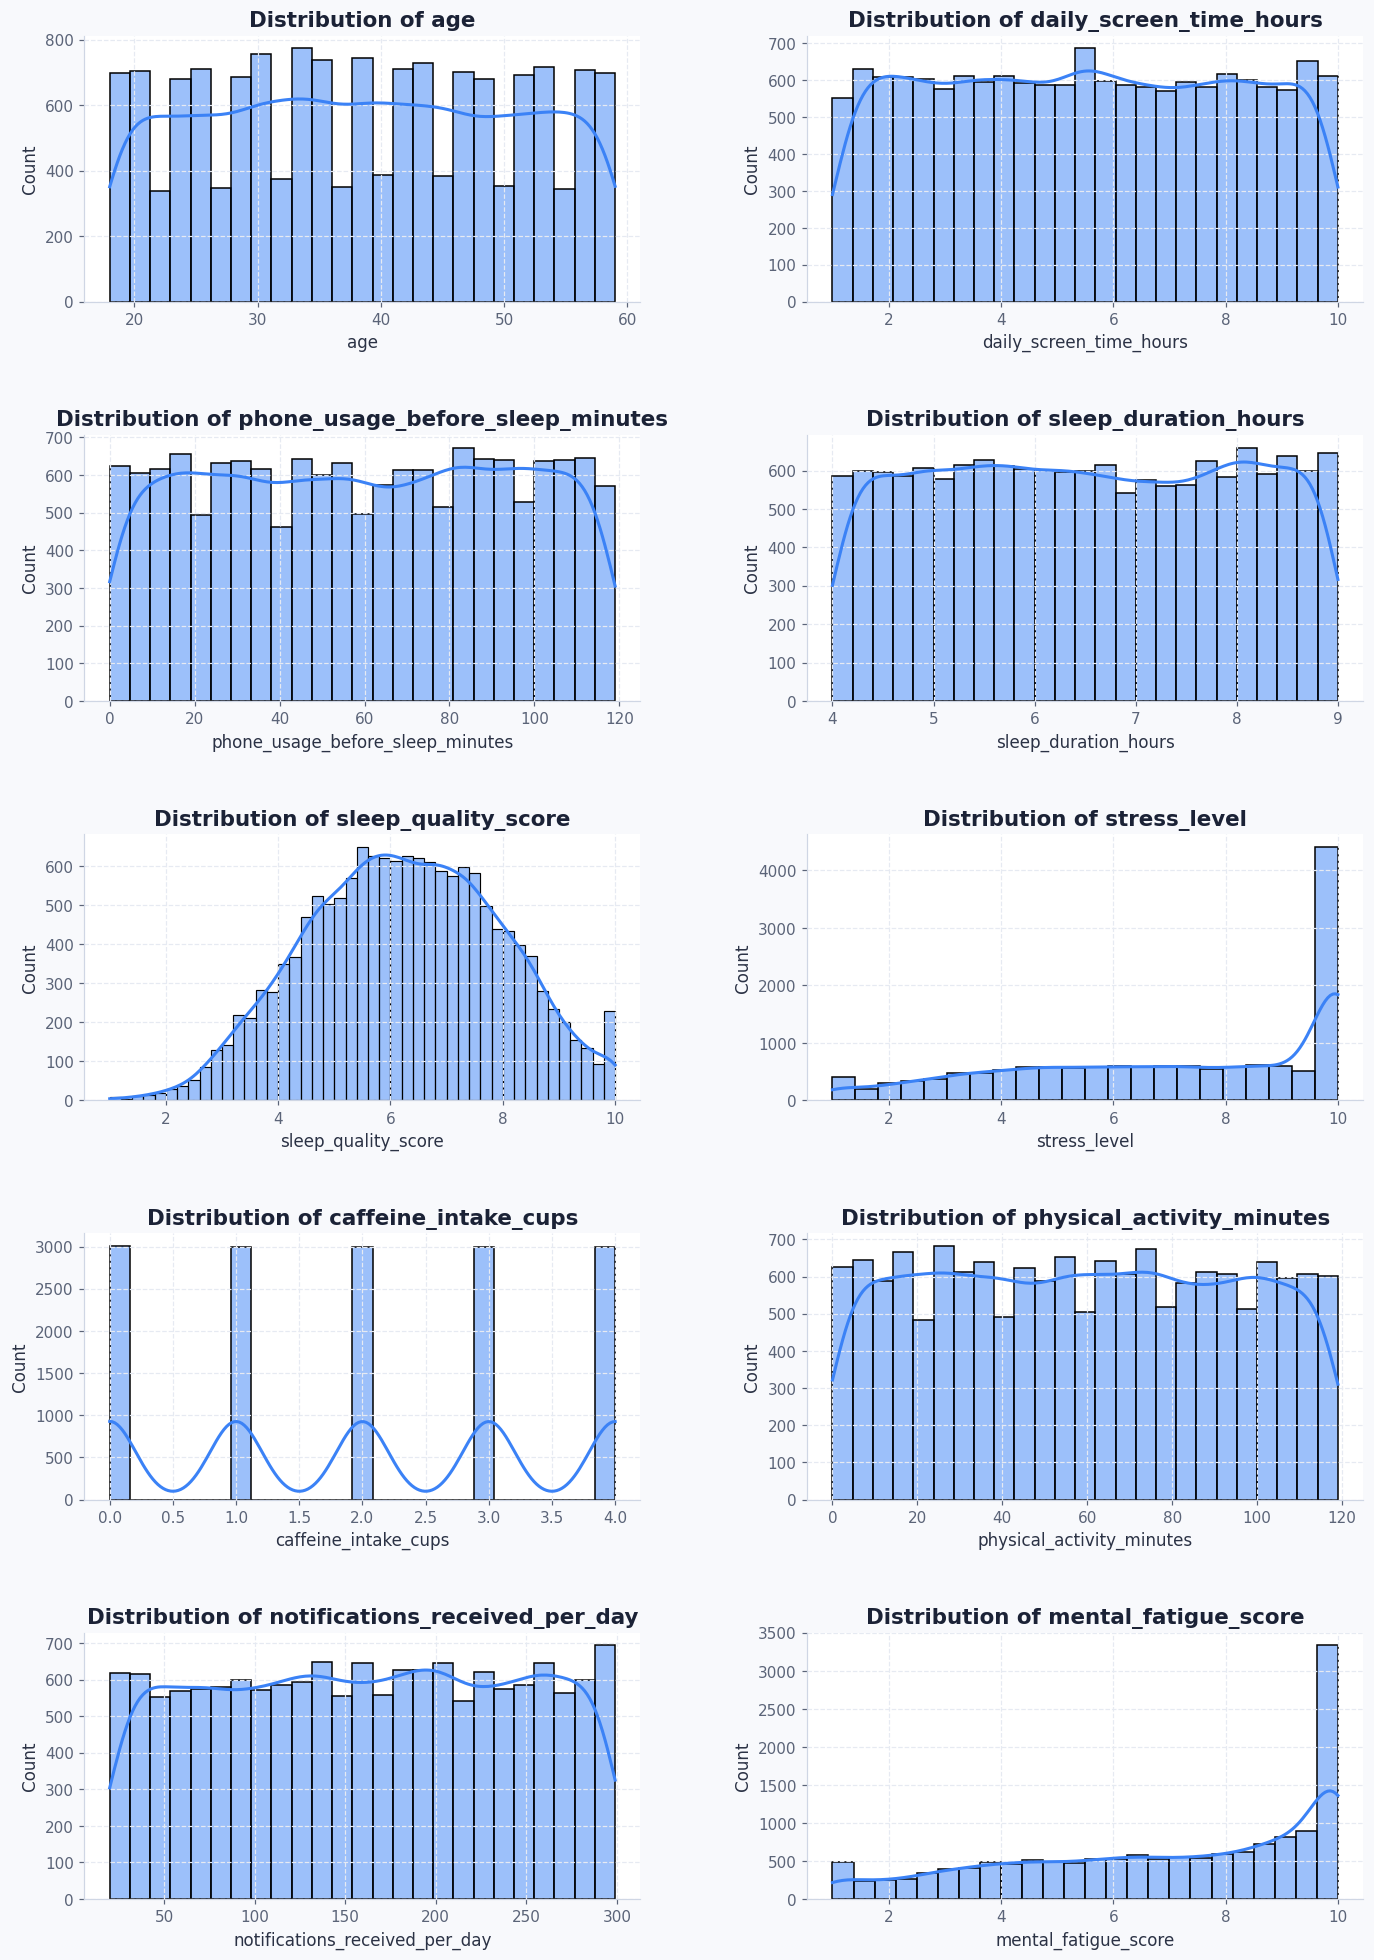

In [11]:
numerical_cols = df.select_dtypes(include=['float64','int64']).drop(columns=['user_id']).columns

fig,axes = plt.subplots(5,2,figsize=(15,22))

for col, ax in zip(numerical_cols,axes.flatten()):
    sns.histplot(data=df,x=col,ax=ax,kde=True)
    ax.set_title(f'Distribution of {col}')

plt.subplots_adjust(hspace=0.5,wspace=0.3)
plt.show()

- `sleep_quality_score` resembles bell-shaped curve
- `mental_fatigue_score` and `stress_level` are Negatively skewed (left skewed)
- `caffeine_intake_cups` has discrete uniform distribution
- Rest of features are approximately uniform distributed
---
- Negatively skewed causes here `celeing_effect` many observations accumulate at the maximum possible value of a measurement

In [12]:
ceil_cols = ['stress_level', 'mental_fatigue_score',
        'sleep_quality_score']

for col in ceil_cols:
    count = (df[col] == 10).sum()
    percentage = count / len(df) * 100

    print(f"{col}: {count} ({percentage:.2f}%)")

stress_level: 3875 (25.83%)
mental_fatigue_score: 2484 (16.56%)
sleep_quality_score: 153 (1.02%)


- `strees_level` and `mental_fatigue_score` have substantial ceiling effect

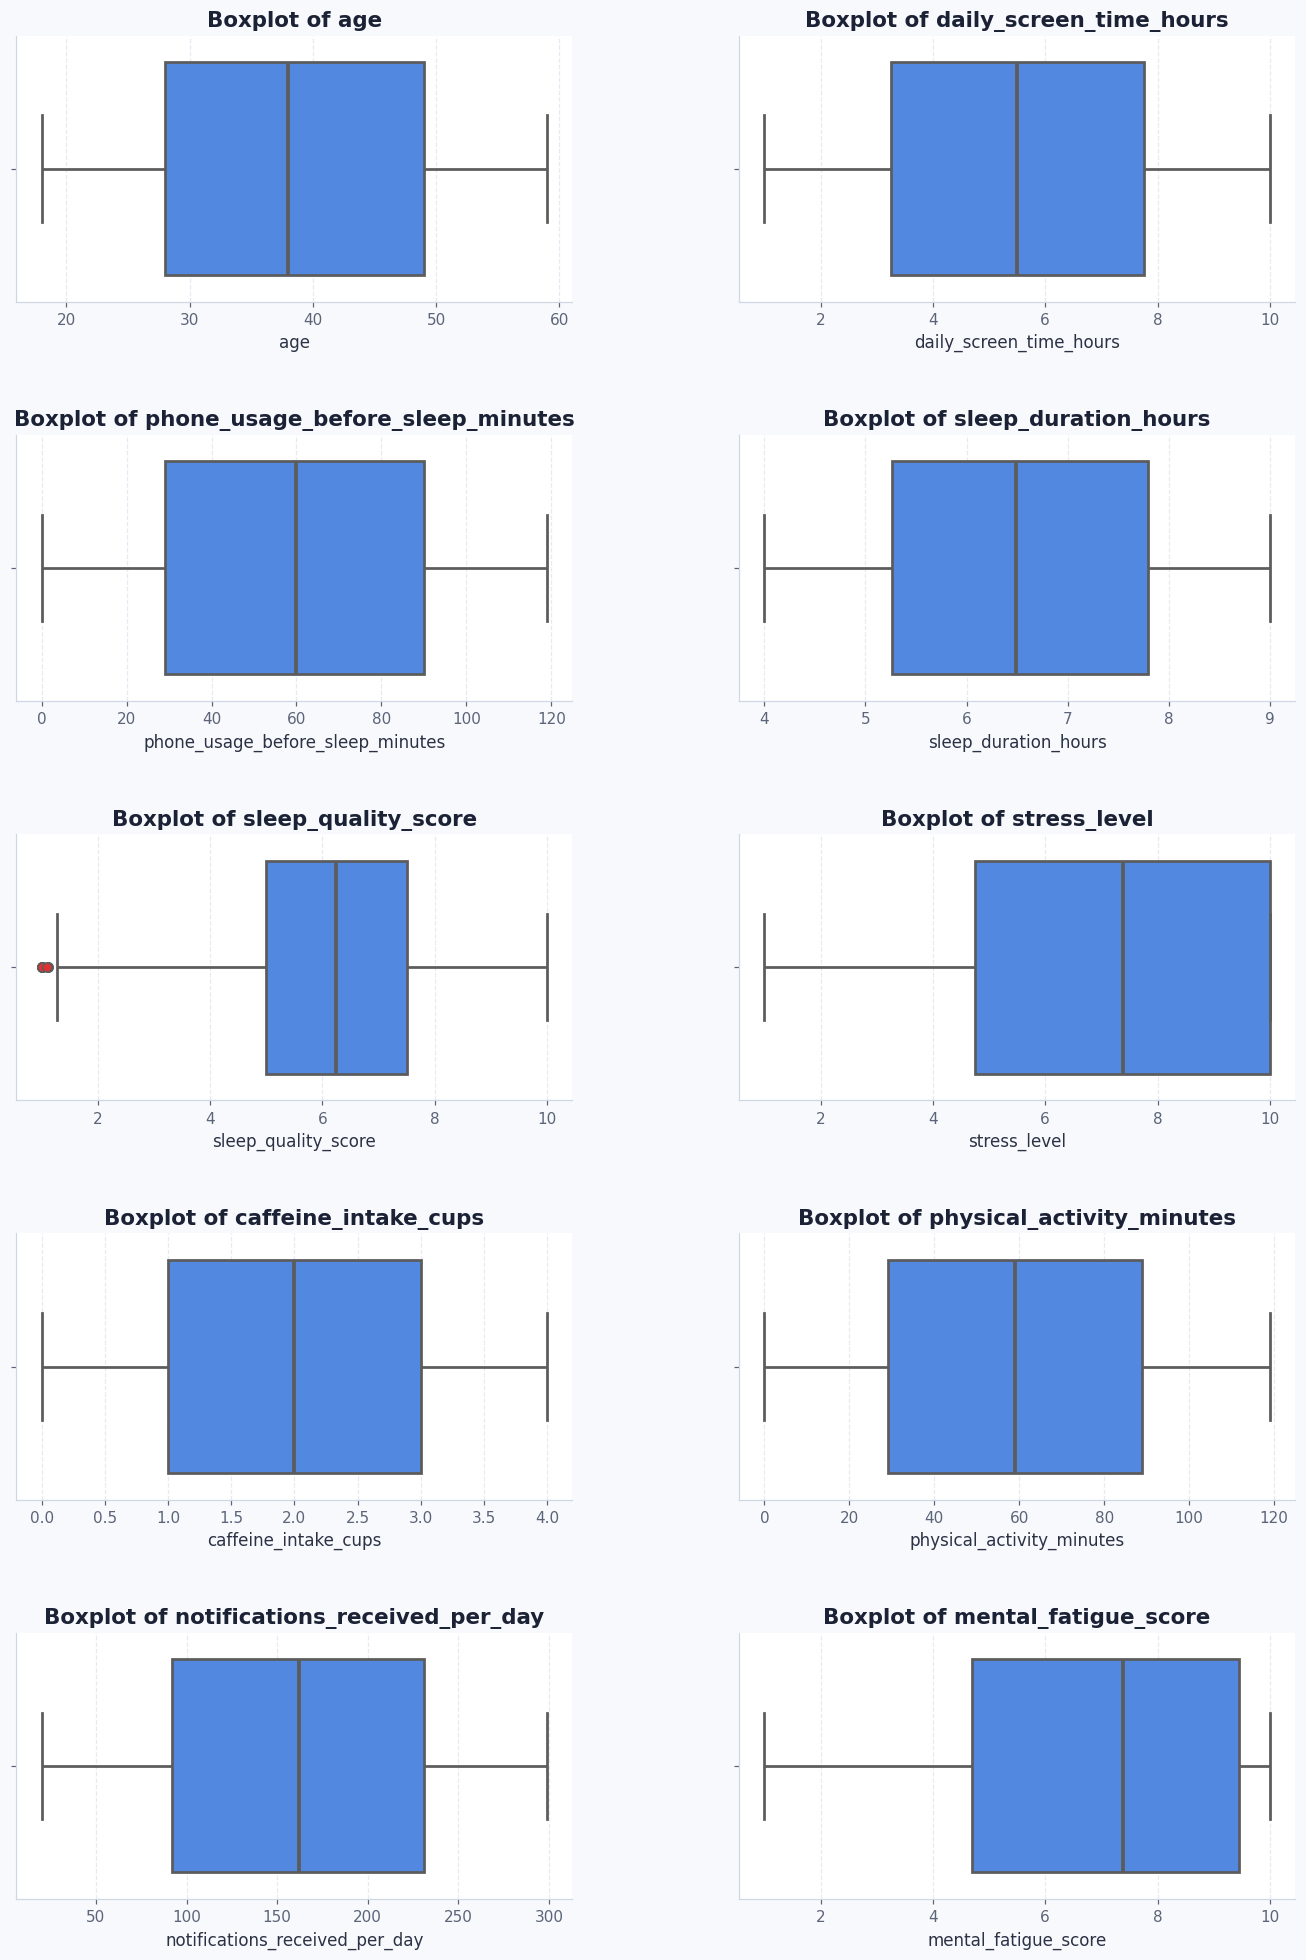

In [13]:
numerical_cols = df.select_dtypes(include=['float64','int64']).drop(columns=['user_id']).columns

fig,axes = plt.subplots(5,2,figsize=(15,22))

for col, ax in zip(numerical_cols,axes.flatten()):
    sns.boxplot(data=df,x=col,ax=ax)
    ax.set_title(f'Boxplot of {col}')

plt.subplots_adjust(hspace=0.5,wspace=0.3)
plt.show()

- Only `sleep_quality_score` has outlier

In [14]:
for col in ceil_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Min value",df[col].min())
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Max value",df[col].max())
    print("Outlier count:", len(outliers))


stress_level
Min value 1.0
Lower bound: -3.12
Upper bound: 17.88
Max value 10.0
Outlier count: 0

mental_fatigue_score
Min value 1.0
Lower bound: -2.42
Upper bound: 16.57
Max value 10.0
Outlier count: 0

sleep_quality_score
Min value 1.0
Lower bound: 1.25
Upper bound: 11.25
Max value 10.0
Outlier count: 9


In [15]:
Q1 = df['sleep_quality_score'].quantile(0.25)
Q3 = df['sleep_quality_score'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['sleep_quality_score'] < lower_bound) |
    (df['sleep_quality_score'] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

display(outliers[['age',
         'daily_screen_time_hours',
         'phone_usage_before_sleep_minutes',
         'sleep_duration_hours',
         'sleep_quality_score',
         'stress_level',
         'mental_fatigue_score']])

Lower bound: 1.25
Upper bound: 11.25
Number of outliers: 9


,age,daily_screen_time_hours,phone_usage_before_sleep_minutes,sleep_duration_hours,sleep_quality_score,stress_level,mental_fatigue_score
253,37,9.63,114,4.64,1.00,10.0,10.00
519,26,9.09,82,7.29,1.00,10.0,10.00
1434,20,9.97,89,6.43,1.11,10.0,9.31
2266,45,9.27,112,4.40,1.00,10.0,10.00
5379,29,9.64,105,4.49,1.00,10.0,10.00
7411,18,9.01,111,8.37,1.00,10.0,10.00
9519,23,9.60,107,8.37,1.11,10.0,8.73
9592,41,9.80,98,8.79,1.00,10.0,10.00
11011,18,9.72,99,8.31,1.09,10.0,8.69


- The IQR method identified nine potential outliers in `sleep_quality_score`.
- They show a combination of high screen time, low sleep quality, high stress and high mental fatigue

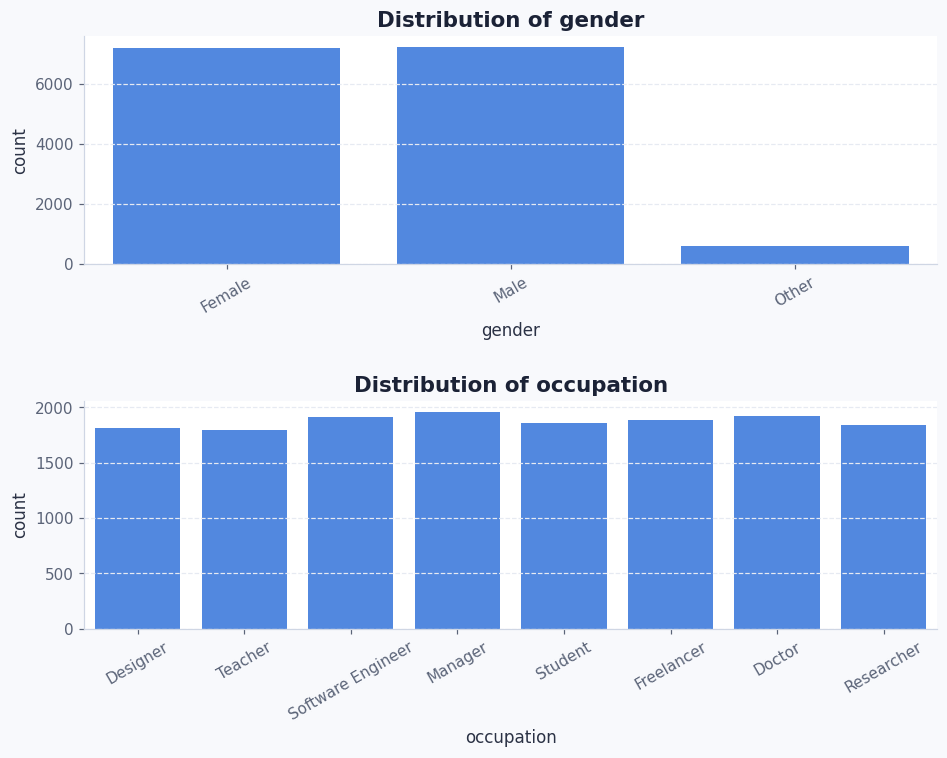

In [16]:
categorical_cols = df.select_dtypes(include=['object']).columns

fig,axes = plt.subplots(2,1,figsize=(10,7))
for col,ax in zip(categorical_cols,axes.flatten()):
    distribution = df[col].value_counts()
    # ax.bar(distribution.index,distribution.values)
    sns.countplot(data=df,x=col,ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis='x',rotation=30)

plt.subplots_adjust(hspace=0.6,wspace=0.3)
plt.show()

**Gender**
- The distribution of Male and Female are equally likely.
- The other category in gender has fewer observation, so slight imbalance between the three categories (Male, Female and Other).

---

**Occupation**
- All eight occupations have relatively similar representation.

### Research Question

**A. Screen Time and Sleep**

1. Does higher daily screen time correspond to shorter sleep duration?

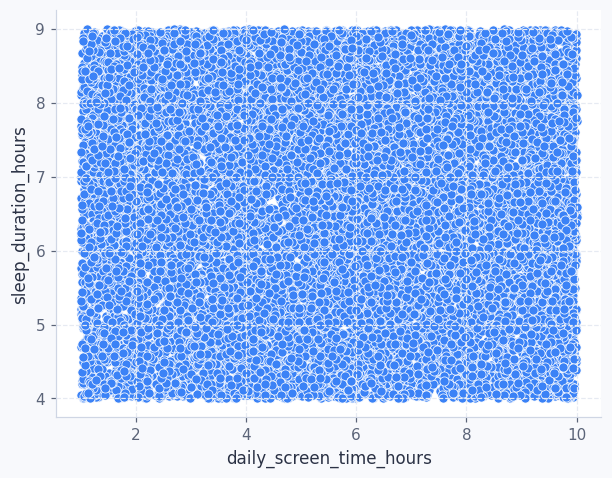

In [17]:
sns.scatterplot(data=df,x='daily_screen_time_hours',y='sleep_duration_hours')
plt.show()

- There is no clearly visible upward or downward trend.

In [18]:
pearson_val = df['daily_screen_time_hours'].corr(df['sleep_duration_hours'],method='pearson')
spearman_val = df['daily_screen_time_hours'].corr(df['sleep_duration_hours'],method='spearman')

print("Pearson coefficient",pearson_val)
print("Spearman coefficient",spearman_val)

Pearson coefficient -0.0018382391592211005
Spearman coefficient -0.0018563203650198354


- Pearson answer: (Linear Association) -- Does X and Y follow a straight-line relationship?
- Spearman answer: (Monotonic Association) -- As X increases, does Y generally increase or decrease, even if the relationship is curved?
- Daily screen time and sleep duration have no *linear* or *monotonic* correlation in this dataset.
- This suggests that higher daily screen time does not correspond to shorter sleep duration in our dataset. However, this finding does not establish that screen time has no effect on sleep in the real world. Because this dataset is synthetic.
---

2. Does increased phone usage before bedtime correspond to lower sleep quality?

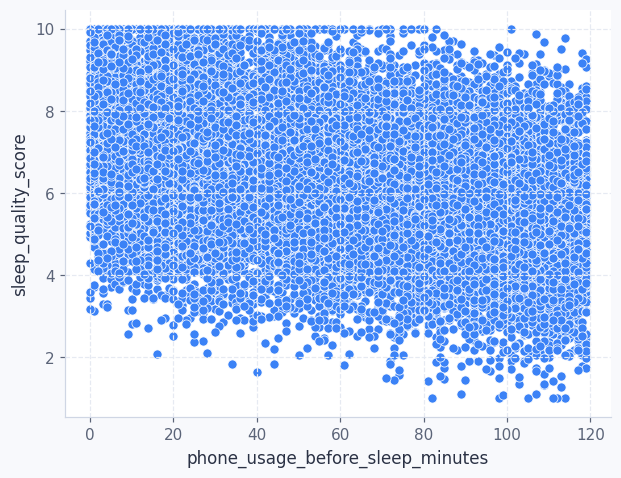

In [19]:
sns.scatterplot(data=df,x="phone_usage_before_sleep_minutes",y="sleep_quality_score")
plt.show()

- No clearly visible pattern, but a downward tendency is visible

In [20]:
pearson_val = df['phone_usage_before_sleep_minutes'].corr(df['sleep_quality_score'],method='pearson')
spearman_val = df['phone_usage_before_sleep_minutes'].corr(df['sleep_quality_score'],method='spearman')

print("Pearson coefficient",pearson_val)
print("Spearman coefficient",spearman_val)

Pearson coefficient -0.33528335231514667
Spearman coefficient -0.3237526515516077


- Weak to moderate linear and monotonic Negative association
- These results suggest that individuals with higher phone usage before sleep tend to report lower sleep quality.

---

3. Is nighttime phone usage more important than total daily screen time in relation to sleep quality?

In [21]:
pearson_val = df['daily_screen_time_hours'].corr(df['sleep_quality_score'],method='pearson')
spearman_val = df['daily_screen_time_hours'].corr(df['sleep_quality_score'],method='spearman')

print("Pearson coefficient",pearson_val)
print("Spearman coefficient",spearman_val)

Pearson coefficient -0.7465309918518422
Spearman coefficient -0.7541433529712305


- Strong negative linear and monotonic association between daily screen time vs sleep quality.
- In this dataset, total screen time appears to be more strongly associated with the sleep quality than phone usage before bedtime.

---
**B. Lifestyle and Stress**

1. Does caffeine consumption relate to higher stress levels?

In [22]:
pearson_val = df['stress_level'].corr(df['caffeine_intake_cups'],method='pearson')
spearman_val = df['stress_level'].corr(df['caffeine_intake_cups'],method='spearman')

print("Pearson coefficient",pearson_val)
print("Spearman coefficient",spearman_val)

Pearson coefficient 0.0034578718400058487
Spearman coefficient 0.00423925954270808


- No linear and monotonic association
- No meaningful evidence of an association between caffeine intake and stress levels in this dataset. So, caffeine consumption doesn't relate to higher stress level.
  
---

2. Does physical activity correspond to lower stress?


In [23]:
pearson_val = df['stress_level'].corr(df['physical_activity_minutes'],method='pearson')
spearman_val = df['stress_level'].corr(df['physical_activity_minutes'],method='spearman')

print("Pearson coefficient",pearson_val)
print("Spearman coefficient",spearman_val)

Pearson coefficient 0.00936015855778892
Spearman coefficient 0.008203854326234548


- This suggests that physical activity does not show a meaningful linear or monotonic relationship with stress levels in this dataset.
- **Caveat**: This does not establish that physical activity has no effect on stress in real-world populations.
---

3. Which lifestyle factors are most strongly associated with stress?


In [24]:
print("Pearson Cofficient")
print(df[numerical_cols].corr()['stress_level'],end='\n\n')

print("Spearman Cofficient")
print(df[numerical_cols].corr(method='spearman')['stress_level'])

Pearson Cofficient
age                                 0.002849
daily_screen_time_hours             0.879001
phone_usage_before_sleep_minutes    0.155330
sleep_duration_hours               -0.004893
sleep_quality_score                -0.857463
stress_level                        1.000000
caffeine_intake_cups                0.003458
physical_activity_minutes           0.009360
notifications_received_per_day     -0.002808
mental_fatigue_score                0.948768
Name: stress_level, dtype: float64

Spearman Cofficient
age                                 0.001525
daily_screen_time_hours             0.893799
phone_usage_before_sleep_minutes    0.153525
sleep_duration_hours               -0.004185
sleep_quality_score                -0.882255
stress_level                        1.000000
caffeine_intake_cups                0.004239
physical_activity_minutes           0.008204
notifications_received_per_day     -0.002973
mental_fatigue_score                0.930688
Name: stress_level, dtype

- Daily screen time & mental fatigue are very strongly positively associated with stress level
- Sleep quality are very strongly negatively associated with stress level.
- Although: These are associations, not evidence that these factors cause changes in stress
---

**C. Combined Analysis**
1. Do people with high screen time and low physical activity experience higher stress?


In [25]:
screen_median = df['daily_screen_time_hours'].median()
activity_median = df['physical_activity_minutes'].median()

df['screen_group'] = np.where(df['daily_screen_time_hours'] > screen_median,"High Screen Time","Low Screen Time")
df['activity_group'] = np.where(df['physical_activity_minutes'] > activity_median,"High Physical Activity","Low Physical Activity")

In [26]:
df.groupby(['screen_group','activity_group'])['stress_level'].agg(['mean','count'])

mean  count
screen_group     activity_group                         
High Screen Time High Physical Activity  9.126898   3756
                 Low Physical Activity   9.136462   3734
Low Screen Time  High Physical Activity  4.862073   3710
                 Low Physical Activity   4.807692   3800

- High Screen time associated with higher stress, regardless of physical activity level.

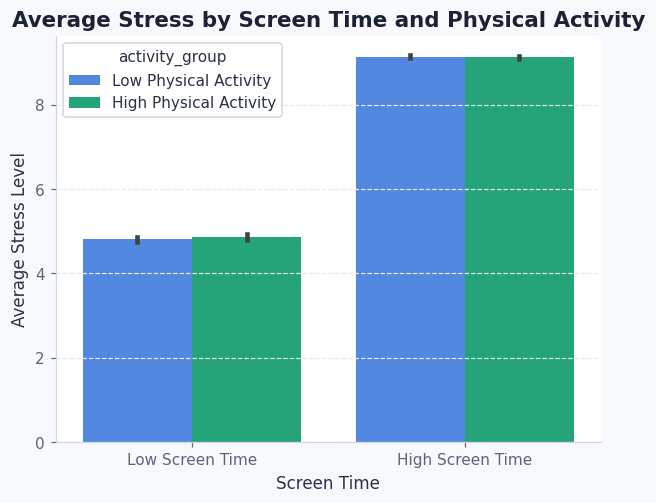

In [27]:
sns.barplot(data=df,x='screen_group',y='stress_level',hue='activity_group')
plt.title('Average Stress by Screen Time and Physical Activity')
plt.ylabel('Average Stress Level')
plt.xlabel('Screen Time')
plt.show()

In [28]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols(
    'stress_level ~ C(screen_group) * C(activity_group)',
    data=df
).fit()

anova_table = sm.stats.anova_lm(model, typ=2)

anova_table

,sum_sq,df,F,PR(>F)
C(screen_group),69234.942262,1.0,23527.503566,0.000000
C(activity_group),1.889669,1.0,0.642150,0.422946
C(screen_group):C(activity_group),3.833058,1.0,1.302555,0.253765
Residual,44129.084551,14996.0,NaN,NaN


- The two-way ANOVA revealed a statistically significant association between screen time and stress levels (p < 0.001). However, physical activity did not show a statistically significant main effect (p = 0.423).

- Additionally, the interaction between screen time and physical activity was not statistically significant (p = 0.254). This suggests that the relationship between screen time and stress does not significantly depend on physical activity level in this dataset.

- Overall, higher screen time is associated with higher stress, but there is insufficient evidence that low physical activity adds to this association.

---

2. Does sleep quality help explain the relationship between screen time and stress?

- From our Previous Analysis

  - Higher screen time is strongly associated with higher stress.
  - Better sleep quality is strongly associated with lower stress.

> Screen Time ⬆️ Stress ⬆️

> Screen Time ⬆️ Sleep Quality ⬇️

In [29]:
# Screen time vs Stress (Analysis)
import statsmodels.formula.api as smf

model_1 = smf.ols(
    'stress_level ~ daily_screen_time_hours',
    data=df
).fit()

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:           stress_level   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                 5.097e+04
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:31:04   Log-Likelihood:                -25345.
No. Observations:               15000   AIC:                         5.069e+04
Df Residuals:                   14998   BIC:                         5.071e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

- Screen time alone explains 77.3% of stress variation.
- The regression coefficient (0.9295) indicates that every additional hour of daily screen time is associated with an average increases of approximately 0.92 points in stress level. This relationship is statistically significant (p < 0.001).

In [30]:
model_2 = smf.ols(
    'sleep_quality_score ~ daily_screen_time_hours',
    data=df
).fit()

print(model_2.summary())

                             OLS Regression Results                            
Dep. Variable:     sleep_quality_score   R-squared:                       0.557
Model:                             OLS   Adj. R-squared:                  0.557
Method:                  Least Squares   F-statistic:                 1.888e+04
Date:                 Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                         05:31:04   Log-Likelihood:                -23251.
No. Observations:                15000   AIC:                         4.651e+04
Df Residuals:                    14998   BIC:                         4.652e+04
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept       

- Daily screen time alone explains approximately 55.7% of the variation in sleep quality in our dataset
- The regression coefficient (-0.4920) indicates that every additional hour of daily screen time is associated with an average decrease of approximately 0.492 points in sleep quality. This relationship is statistically significant (p < 0.001).

In [31]:
model_3 = smf.ols(
    'stress_level ~ daily_screen_time_hours + sleep_quality_score',
    data=df
).fit()

print(model_3.summary())

                            OLS Regression Results                            
Dep. Variable:           stress_level   R-squared:                       0.864
Model:                            OLS   Adj. R-squared:                  0.864
Method:                 Least Squares   F-statistic:                 4.770e+04
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:31:04   Log-Likelihood:                -21483.
No. Observations:               15000   AIC:                         4.297e+04
Df Residuals:                   14997   BIC:                         4.300e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

- Model 1: Screen time -> Stress; Screen_time_cofficient (`+0.9295`)
- Model 3: Screen time + Sleep Quality -> Stress; Screen_time_cofficient (`+0.5706`)
- The coefficient decreased by approximately `38.6%` after including sleep quality; `(0.9295-0.5706)/0.9295 = 0.386`
---
- In model 1, every additional hour of screen time was associated with a `0.9295` point increase in stress.
- In model 2, every additional hour of screen time was associated with `0.4920` point decrease in sleep quality.
- In model 3, every addittional hour of screen time was associated with only `0.57` increase in stress. Our stress increase is going to lower after adding sleep quality.
- Means, Sleep Quality accounts in statiscally for part of the association between screen time and stress.

In [32]:
import numpy as np
import statsmodels.formula.api as smf

# Original indirect effect
model_a = smf.ols(
    'sleep_quality_score ~ daily_screen_time_hours',
    data=df
).fit()

model_b = smf.ols(
    'stress_level ~ daily_screen_time_hours + sleep_quality_score',
    data=df
).fit()

a = model_a.params['daily_screen_time_hours']
b = model_b.params['sleep_quality_score']

indirect_effect = a * b

print("Indirect effect:", indirect_effect)

Indirect effect: 0.35888484167888984


In [33]:
np.random.seed(42)

n_iterations = 1000
indirect_effects = []

for i in range(n_iterations):

    # Randomly sample rows with replacement
    sample = df.sample(
        n=len(df),
        replace=True
    )

    # Path a
    model_a = smf.ols(
        'sleep_quality_score ~ daily_screen_time_hours',
        data=sample
    ).fit()

    # Path b
    model_b = smf.ols(
        'stress_level ~ daily_screen_time_hours + sleep_quality_score',
        data=sample
    ).fit()

    # Indirect effect
    a = model_a.params['daily_screen_time_hours']
    b = model_b.params['sleep_quality_score']

    indirect_effects.append(a * b)

# Calculate 95% confidence interval
lower_bound = np.percentile(indirect_effects, 2.5)
upper_bound = np.percentile(indirect_effects, 97.5)

print("Bootstrap indirect effect:", np.mean(indirect_effects))
print("95% CI:", lower_bound, upper_bound)

Bootstrap indirect effect: 0.358883100032835
95% CI: 0.3501148128884914 0.36721198670337707
